# v15 — Economic Signal Redesign
**Naming note:** `v14` is the completed CRISIL submission layer. To preserve it, this redesign is **v15**. All of v1–v14 is untouched.

**Objective (unchanged, from the brief):** identify which of the five Developed Markets are likely to out- or under-perform over the next 3–6 months.

**What is different here.** v1–v13 searched narrow signal constructions and optimised portfolio Sharpe. This layer starts from the data itself, then builds a **small, pre-declared set of economically motivated constructions** per pillar, and tests them with a cross-country research design (within-country point-in-time standardisation, removal of persistent country bias, walk-forward, leave-one-country-out, overlapping-return inference).

**Data policy:** only the original assignment workbooks. No external observations. No silent replacement of missing values.

**Honesty note carried throughout:** the 2017–2026 window was examined repeatedly in v1–v13. It is labelled **EXAMINED**, never "untouched holdout".

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, json, subprocess
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import rankdata
from IPython.display import display
warnings.filterwarnings('ignore')
pd.options.display.float_format = '{:,.3f}'.format; pd.options.display.width = 250; pd.options.display.max_columns = 40; pd.options.display.max_rows = 250
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
ROOT = Path('..').resolve(); OUT = ROOT/'output'/'v15'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)
COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']; SEED = 7; NBOOT = 2000
FILES = {'US': 'US_raw_data.xlsx', 'Eurozone': 'EUR_raw_data.xlsx', 'UK': 'UK_raw_data.xlsx', 'Switzerland': 'CH_raw_data.xlsx', 'Japan': 'JPY_raw_data.xlsx'}
print('git HEAD:', subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=ROOT, capture_output=True, text=True).stdout.strip())
LOG = []
def log(step, test, finding, decision):
    LOG.append(dict(step=step, test=test, finding=finding, decision=decision))

git HEAD: f64ec34


## 1. Data audit — dictionary built from the files, not from memory

In [2]:
def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    d['_date'] = pd.to_datetime(d['Date'])
    return d.sort_values('_date').drop_duplicates('month', keep='last').set_index('month')
RAW = {c: monthly(pd.read_excel(ROOT/'data'/'raw'/f)) for c, f in FILES.items()}
MEANING = {
 'BEst P/E Ratio': ('Bloomberg consensus 12M-forward price/earnings ratio', 'ratio (x)', 'valuation'),
 'Monthly_EPS': ('US 12M-forward consensus earnings per share', 'index points', 'earnings'),
 'BEst EPS': ('Bloomberg consensus 12M-forward earnings per share', 'local index points', 'earnings'),
 'GSFCI Index': ('Goldman Sachs US Financial Conditions Index (higher = TIGHTER)', 'index, ~100 = neutral', 'financial conditions'),
 'GSGBFCI Index': ('Goldman Sachs UK Financial Conditions Index (higher = TIGHTER)', 'index, ~100 = neutral', 'financial conditions'),
 'GSEAFCI Index': ('Goldman Sachs EURO-AREA Financial Conditions Index (higher = TIGHTER)', 'index, ~100 = neutral', 'financial conditions'),
 'GSJPFCI Index': ('Goldman Sachs Japan Financial Conditions Index (higher = TIGHTER)', 'index, ~100 = neutral', 'financial conditions'),
 'BFCIEU Index': ('Bloomberg Euro-area Financial Conditions Index (higher = EASIER)', 'z-score vs history', 'financial conditions'),
 'NAPMPMI Index': ('ISM US manufacturing PMI', 'diffusion index, 50 = no change', 'activity'),
 'MPMIEZMA Index': ('S&P Global Eurozone manufacturing PMI', 'diffusion index', 'activity'),
 'MPMIGBMA Index': ('S&P Global UK manufacturing PMI', 'diffusion index', 'activity'),
 'CH_PMI': ('Switzerland procure.ch manufacturing PMI', 'diffusion index', 'activity'),
 'JPYPMI': ('Japan manufacturing PMI', 'diffusion index', 'activity'),
 'USGGT02Y Index': ('US 2Y Treasury yield', '% p.a.', 'rates'),
 'GDBR2 Index': ('German 2Y Bund yield', '% p.a.', 'rates'),
 'GUKG2 Index': ('UK 2Y Gilt yield', '% p.a.', 'rates'),
 'GSWISS02 Index': ('Swiss 2Y government yield', '% p.a.', 'rates'),
 'GJGB2 Index': ('Japan 2Y JGB yield', '% p.a.', 'rates'),
 'LF98OAS Index': ('US HIGH-YIELD corporate OAS', '% (spread)', 'credit'),
 'LECPOAS Index': ('Euro investment-grade corporate OAS', '% (spread)', 'credit'),
 'LC61OAS Index': ('Sterling investment-grade corporate OAS', '% (spread)', 'credit'),
 'LJC1OAS Index': ('Yen investment-grade corporate OAS', '% (spread)', 'credit'),
 'DXY Index': ('US dollar index vs major currencies', 'index', 'FX'),
 'EURUSD BGN Curncy': ('EUR per USD quoted USD/EUR (USD per 1 EUR)', 'rate', 'FX'),
 'GBPUSD BGN Curncy': ('USD per 1 GBP', 'rate', 'FX'),
 'USDCHF Curncy': ('CHF per 1 USD', 'rate', 'FX'),
 'EURCHF Curncy': ('CHF per 1 EUR', 'rate', 'FX'),
 'USDJPY BGN Curncy': ('JPY per 1 USD', 'rate', 'FX'),
 'VIX Index': ('CBOE VIX (US equity implied volatility) — GLOBAL variable', 'index', 'volatility'),
 'V2X Index': ('EURO STOXX 50 implied volatility', 'index', 'volatility'),
 'CO1 Comdty': ('Brent crude front-month — GLOBAL variable', 'USD/bbl', 'commodity'),
 'CL1 Comdty (YEN)': ('WTI front-month priced in yen — GLOBAL variable in JPY', 'JPY/bbl', 'commodity'),
}
LAG = {'activity': '1 month (PMI for month M is published early in M+1)', 'earnings': '0 (live consensus; vintage unverifiable)',
       'valuation': '0 (live consensus; vintage unverifiable)', 'financial conditions': '0 (daily, real-time)', 'rates': '0 (market)',
       'credit': '0 (market)', 'FX': '0 (market)', 'volatility': '0 (market)', 'commodity': '0 (market)'}
rows = []
for c, d in RAW.items():
    for col in [x for x in d.columns if x not in ('Date', '_date', 'month')]:
        s = d[col]; v = s.dropna()
        if not len(v): continue
        fv, lv = s.first_valid_index(), s.last_valid_index()
        mean, unit, fam = MEANING.get(col, ('UNMAPPED', '?', 'other'))
        rows.append({'market': c, 'variable': col, 'economic meaning': mean, 'units': unit, 'family': fam,
                     'frequency': 'monthly (last obs in month)', 'first month': str(fv), 'last month': str(lv), 'n months': len(v),
                     'internal missing': int(s.loc[fv:lv].isna().sum()), 'distinct values': v.nunique(),
                     'share months unchanged': float((v.diff() == 0).mean()), 'reporting lag applied': LAG[fam]})
DICT = pd.DataFrame(rows)
display(DICT.set_index(['market', 'variable']))
DICT.to_csv(OUT/'data_dictionary.csv', index=False)
print(f'{len(DICT)} series across {len(RAW)} workbooks; unmapped variables: {sorted(set(DICT.loc[DICT["economic meaning"] == "UNMAPPED", "variable"]))}')

economic meaning                            units                family                    frequency first month last month  n months  internal missing  distinct values  \
market      variable                                                                                                                                                                                                                       
US          BEst P/E Ratio     Bloomberg consensus 12M-forward price/earnings...                        ratio (x)             valuation  monthly (last obs in month)     2005-01    2026-04       256                 0              256   
            Monthly_EPS              US 12M-forward consensus earnings per share                     index points              earnings  monthly (last obs in month)     2005-01    2026-04       256                 0              256   
            DXY Index                        US dollar index vs major currencies                            index                    FX  monthly (last obs in month)     2005-01    2026-04       256                 0              255   
            LF98OAS Index                            US HIGH-YIELD corporate OAS                       % (spread)                credit  monthly (last obs in month)     2005-01    2026-04       256                 0              202   
            CO1 Comdty                 Brent crude front-month — GLOBAL variable                          USD/bbl             commodity  monthly (last obs in month)     2005-01    2026-04       256                 0              251   
            VIX Index          CBOE VIX (US equity implied volatility) — GLOB...                            index            volatility  monthly (last obs in month)     2005-01    2026-04       256                 0              242   
            USGGT02Y Index                                  US 2Y Treasury yield                           % p.a.                 rates  monthly (last obs in month)     2005-01    2026-04       256                 0              254   
            NAPMPMI Index                               ISM US manufacturing PMI  diffusion index, 50 = no change              activity  monthly (last obs in month)     2005-01    2026-04       256                 0              130   
            GSFCI Index        Goldman Sachs US Financial Conditions Index (h...            index, ~100 = neutral  financial conditions  monthly (last obs in month)     2005-01    2026-04       256                 0              165   
Eurozone    BEst P/E Ratio     Bloomberg consensus 12M-forward price/earnings...                        ratio (x)             valuation  monthly (last obs in month)     2005-12    2026-06       247                 0              246   
            BEst EPS           Bloomberg consensus 12M-forward earnings per s...               local index points              earnings  monthly (last obs in month)     2005-12    2026-06       247                 0              245   
            EURUSD BGN Curncy         EUR per USD quoted USD/EUR (USD per 1 EUR)                             rate                    FX  monthly (last obs in month)     1996-07    2026-06       360                 0              348   
            MPMIEZMA Index                 S&P Global Eurozone manufacturing PMI                  diffusion index              activity  monthly (last obs in month)     1997-06    2026-06       349                 0              138   
            GDBR2 Index                                     German 2Y Bund yield                           % p.a.                 rates  monthly (last obs in month)     1996-07    2026-06       360                 0              339   
            V2X Index                           EURO STOXX 50 implied volatility                            index            volatility  monthly (last obs in month)     1999-01    2026-06       330                 0              328   
            BFCIEU Index       Bloomberg Euro-area F

46 series across 5 workbooks; unmapped variables: []


### 1a. Shared, duplicated and global series
A variable that is the *same observation* in several workbooks carries no cross-country information: in a five-market cross-section it is a constant and its z-score is undefined or noise.

In [3]:
def same(a, b):
    j = pd.concat([a.rename('a'), b.rename('b')], axis=1).dropna()
    return len(j), float((j.a - j.b).abs().max()), float(j.a.corr(j.b))
shared = []
vix = {c: RAW[c]['VIX Index'] for c in RAW if 'VIX Index' in RAW[c].columns}
for c in vix:
    if c == 'US': continue
    n, mx, r = same(vix[c], vix['US']); shared.append({'series': 'VIX Index', 'market': c, 'compared with': 'US VIX', 'overlap months': n, 'max abs diff': mx, 'correlation': r})
oil = {c: RAW[c]['CO1 Comdty'] for c in RAW if 'CO1 Comdty' in RAW[c].columns}
for c in oil:
    if c == 'US': continue
    n, mx, r = same(oil[c], oil['US']); shared.append({'series': 'CO1 Comdty', 'market': c, 'compared with': 'US CO1', 'overlap months': n, 'max abs diff': mx, 'correlation': r})
n, mx, r = same(RAW['Switzerland']['LECPOAS Index'], RAW['Eurozone']['LECPOAS Index'])
shared.append({'series': 'LECPOAS Index', 'market': 'Switzerland', 'compared with': 'Eurozone LECPOAS', 'overlap months': n, 'max abs diff': mx, 'correlation': r})
SHARED = pd.DataFrame(shared).set_index(['series', 'market']); display(SHARED)
SHARED.to_csv(OUT/'shared_series.csv')
print('VIX is IDENTICAL across the US, Swiss and Japanese workbooks -> it is one global observation, not three country readings.')
print('Brent (CO1) is the same series in four workbooks (0.25 vintage difference) -> also global.')
print("Switzerland's credit spread IS the euro-area LECPOAS -> Switzerland has no own credit series.")

compared with  overlap months  max abs diff  correlation
series        market                                                                  
VIX Index     UK                     US VIX             256        44.590        0.052
              Switzerland            US VIX             245         0.000        1.000
              Japan                  US VIX             251         0.000        1.000
CO1 Comdty    Eurozone               US CO1             256         0.250        1.000
              UK                     US CO1             256         0.250        1.000
              Switzerland            US CO1             245         0.250        1.000
LECPOAS Index Switzerland  Eurozone LECPOAS             247         0.000        1.000

VIX is IDENTICAL across the US, Swiss and Japanese workbooks -> it is one global observation, not three country readings.
Brent (CO1) is the same series in four workbooks (0.25 vintage difference) -> also global.
Switzerland's credit spread IS the euro-area LECPOAS -> Switzerland has no own credit series.


### 1b. The UK workbook's "VIX Index" column is not an equity volatility index

In [4]:
ukv = RAW['UK']['VIX Index'].dropna(); usv = RAW['US']['VIX Index']
STRESS = pd.DataFrame({'UK workbook "VIX" column': ukv, 'true VIX (US/CH/JP workbooks)': usv}).loc[['2008-09', '2008-10', '2008-11', '2020-02', '2020-03', '2020-04']]
display(STRESS.round(2))
print(f'Correlation with the true VIX: {ukv.corr(usv.reindex(ukv.index)):.3f}. Range {ukv.min():.2f}-{ukv.max():.2f} vs true VIX {usv.min():.2f}-{usv.max():.2f}.')
print('Reversing the column order (the workbook is stored newest-first) does not reconcile it either (correlation 0.20).')
print('An equity volatility index MUST spike in Oct-2008 and Mar-2020; this series does not. It is an unidentified variable.')
log('audit', 'UK workbook "VIX Index" column vs true VIX', f'corr {ukv.corr(usv.reindex(ukv.index)):.2f}, no 2008/2020 spike, range 13.5-31.1',
    'EXCLUDED. Not identifiable from the workbook, so it cannot be used as an input.')
log('audit', 'VIX identical across US/CH/JP workbooks', 'max abs diff 0.00',
    'VIX/V2X are GLOBAL variables. Not used as country-level signals (per instruction); available only as a regime conditioner.')

,"UK workbook ""VIX"" column",true VIX (US/CH/JP workbooks)
month,,
2008-09,16.350,39.390
2008-10,15.300,59.890
2008-11,15.180,55.840
2020-02,22.370,40.110
2020-03,25.090,53.540
2020-04,24.060,34.150


Correlation with the true VIX: 0.052. Range 13.47-31.05 vs true VIX 9.51-59.89.
Reversing the column order (the workbook is stored newest-first) does not reconcile it either (correlation 0.20).
An equity volatility index MUST spike in Oct-2008 and Mar-2020; this series does not. It is an unidentified variable.


### 1c. The combined price workbook — the assignment's Price identifiers versus the actual values
The brief's data table lists price tickers (SPX, MXEM, MXGB, MXCH, MXJP). The workbook's columns carry those labels but **the values are valuation ratios, not index levels**.

In [5]:
pf = pd.read_excel(ROOT/'data'/'raw'/'Price_data_all_countries.xlsx')
rows = []
for dcol, vcol in [('US', 'SPX Index'), ('Eurozone ', 'MXEM Index'), ('UK', 'MXGB Index'), ('Switzerland', 'MXCH Index'), ('Japan', 'MXJP Index')]:
    c = dcol.strip(); s = pf[[dcol, vcol]].dropna(); s.index = pd.to_datetime(s[dcol]).dt.to_period('M'); s = s[~s.index.duplicated(keep='last')][vcol]
    j = pd.concat([s.rename('file'), RAW[c]['BEst P/E Ratio'].rename('pe')], axis=1).dropna()
    rows.append({'labelled ticker': vcol, 'market': c, 'first month': str(s.index.min()), 'last month': str(s.index.max()), 'n': len(s),
                 'value range': f'{s.min():.1f} – {s.max():.1f}', 'plausible index level?': 'NO',
                 'median |col − BEst P/E|': float((j.file - j.pe).abs().median()), 'max |col − BEst P/E|': float((j.file - j.pe).abs().max()),
                 'corr of monthly changes with BEst P/E': float(j.file.diff().corr(j.pe.diff()))})
PRICEF = pd.DataFrame(rows).set_index('market'); display(PRICEF)
PRICEF.to_csv(OUT/'price_file_forensics.csv')
print('Findings:')
print(' 1. Every column ranges 8-39. A genuine SPX level is ~700-6,000 and MXJP ~800-2,000. These are P/E RATIOS.')
print(' 2. They track each workbook\'s BEst P/E closely (median difference ~0.00) but not exactly (max 0.06-0.29),')
print('    so the workbook holds a SECOND, slightly different vintage of the same valuation quantity - not a price.')
print(' 3. CONSEQUENCE: the dataset contains NO genuine index price series for any market.')
log('audit', 'Combined price workbook vs the brief\'s price tickers',
    'All five columns are P/E ratios (range 8-39), near-identical to each workbook\'s BEst P/E; no index levels anywhere in the dataset',
    'Technical pillar cannot use observed prices. A clearly labelled price PROXY is constructed in §2 and its dependence on EPS and P/E is stated, not denied.')

,labelled ticker,first month,last month,n,value range,plausible index level?,median |col − BEst P/E|,max |col − BEst P/E|,corr of monthly changes with BEst P/E
market,,,,,,,,,
US,SPX Index,2000-01,2026-07,319,10.5 – 24.8,NO,0.004,0.055,1.000
Eurozone,MXEM Index,2005-12,2026-07,248,8.0 – 18.3,NO,0.000,0.169,1.000
UK,MXGB Index,2005-12,2026-07,248,7.7 – 16.1,NO,0.000,0.287,0.999
Switzerland,MXCH Index,2005-12,2026-07,248,10.4 – 20.4,NO,0.000,0.100,1.000
Japan,MXJP Index,2005-06,2026-07,254,11.1 – 39.2,NO,0.000,0.190,1.000


Findings:
 1. Every column ranges 8-39. A genuine SPX level is ~700-6,000 and MXJP ~800-2,000. These are P/E RATIOS.
 2. They track each workbook's BEst P/E closely (median difference ~0.00) but not exactly (max 0.06-0.29),
    so the workbook holds a SECOND, slightly different vintage of the same valuation quantity - not a price.
 3. CONSEQUENCE: the dataset contains NO genuine index price series for any market.


## 2. Panel, targets and the research design
### 2a. Panel and the return target
No genuine index price exists (§1c), so the return target is itself a **proxy**: implied index level = forward P/E × forward EPS, converted to USD.
This is an accounting identity (P/E ≡ Price/EPS), and v4 verified the US series against published S&P 500 monthly returns to 0.04 pp. It is a **price** return: no dividends are supplied.

In [6]:
SPEC = {'US': dict(eps='Monthly_EPS', fci=('GSFCI Index', -1), pmi='NAPMPMI Index', y2='USGGT02Y Index', oas='LF98OAS Index', fx=None),
        'Eurozone': dict(eps='BEst EPS', fci=('BFCIEU Index', +1), pmi='MPMIEZMA Index', y2='GDBR2 Index', oas='LECPOAS Index', fx=('EURUSD BGN Curncy', 'direct')),
        'UK': dict(eps='BEst EPS', fci=('GSGBFCI Index', -1), pmi='MPMIGBMA Index', y2='GUKG2 Index', oas='LC61OAS Index', fx=('GBPUSD BGN Curncy', 'direct')),
        'Switzerland': dict(eps='BEst EPS', fci=('GSEAFCI Index', -1), pmi='CH_PMI', y2='GSWISS02 Index', oas='LECPOAS Index', fx=('USDCHF Curncy', 'invert')),
        'Japan': dict(eps='BEst EPS', fci=('GSJPFCI Index', -1), pmi='JPYPMI', y2='GJGB2 Index', oas='LJC1OAS Index', fx=('USDJPY BGN Curncy', 'invert'))}
def grab(c, k):
    s = SPEC[c]; d = RAW[c]
    if k == 'fci': return s['fci'][1] * d[s['fci'][0]]                       # oriented: higher = EASIER
    if k == 'fx': return pd.Series(1.0, index=d.index) if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return d[{'pe': 'BEst P/E Ratio', 'eps': s['eps'], 'pmi': s['pmi'], 'y2': s['y2'], 'oas': s['oas']}[k]]
IDX = pd.period_range(max(grab(c, 'pe').first_valid_index() for c in COUNTRIES), min(RAW[c].index.max() for c in COUNTRIES), freq='M')
PE, EPS, FCI, PMI, Y2, OAS, FX = [pd.DataFrame({c: grab(c, k) for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'fci', 'pmi', 'y2', 'oas', 'fx')]
PX = PE * EPS; PX_USD = PX * FX; AS_OF = IDX[-1]
print(f'Panel {IDX[0]} -> {AS_OF} ({len(IDX)} months). Missing cells inside the panel: ' +
      ', '.join(f'{n}={int(d.isna().sum().sum())}' for n, d in [('PE', PE), ('EPS', EPS), ('FCI', FCI), ('PMI', PMI), ('2Y', Y2), ('OAS', OAS), ('FX', FX)]))
def rel(df, h):
    r = df.shift(-h) / df - 1; return r.sub(r.mean(axis=1), axis=0)
TGT = {('ret', h): rel(PX_USD, h) for h in (3, 6)} | {('mult', h): rel(PE, h) for h in (3, 6)} | {('earn', h): rel(EPS, h) for h in (3, 6)}
print('Targets: relative USD price return (ret), relative P/E change (mult), relative EPS change (earn), at 3M and 6M.')

Panel 2005-12 -> 2026-04 (245 months). Missing cells inside the panel: PE=0, EPS=0, FCI=0, PMI=0, 2Y=0, OAS=0, FX=0
Targets: relative USD price return (ret), relative P/E change (mult), relative EPS change (earn), at 3M and 6M.


### 2b. Standardisation — the central design choice
Two routes are tested for **every** construction, because this is the hypothesis that v1–v13 never isolated:

| Route | Definition | What it does |
|---|---|---|
| **CS** (v13 style) | cross-sectional z across the five markets each month | keeps persistent country level differences — a market that is structurally high always scores high |
| **PIT→CS** (new) | within-country expanding z using only data up to t (≥36 obs), then cross-sectional z | measures each market **against its own history**, so persistent country bias is removed and only genuine change is scored |

Both use information available at month-end t only. The expanding window never sees the future.

In [7]:
cs_z = lambda d: d.sub(d.mean(axis=1), axis=0).div(d.std(axis=1, ddof=1), axis=0).where(d.notna().all(axis=1))
def pit_z(d, mp=36):
    """within-country expanding z using data up to and including t"""
    return (d - d.expanding(mp).mean()) / d.expanding(mp).std()
def pit_demean(d, mp=36):
    return d - d.expanding(mp).mean()
own_sd = lambda d, mp=36: d / d.expanding(mp).std()

## 3. Pillar redesign — pre-declared hypothesis set
Constructions are declared here **before** any result is seen. 24 constructions in total (6 Macro × 2 routes is counted once; see table). No combinatorial search.

In [8]:
PMI_L = PMI.shift(1)                                  # publication lag: PMI for month M is released early in M+1
MACRO = {
 'M1 FCI easing 6M (v13 baseline)':        FCI - FCI.shift(6),
 'M2 PMI momentum 3M (lagged 1M)':         PMI_L - PMI_L.shift(3),
 'M3 PMI level vs 50 (lagged 1M)':         PMI_L - 50.0,
 'M4 Credit spread tightening 6M':        -(OAS - OAS.shift(6)),
 'M5 2Y yield decline 6M':                -(Y2 - Y2.shift(6)),
}
MICRO = {
 'Mi1 EPS revision 6M (v13 baseline)':     EPS / EPS.shift(6) - 1,
 'Mi2 EPS revision 3M':                    EPS / EPS.shift(3) - 1,
 'Mi3 EPS revision acceleration':         (EPS / EPS.shift(3) - 1) - (EPS.shift(3) / EPS.shift(6) - 1),
}
EY = 100.0 / PE                                       # forward earnings yield, %
VAL = {
 'V1 P/E vs peers (v13/v14 baseline)':    -PE.div(PE.mean(axis=1), axis=0),
 'V2 Earnings yield (1 / forward P/E)':    EY,
 'V3 Valuation spread (EY − 2Y yield)':    EY - Y2,
}
RLOC = PX.pct_change()
def trend_q(P, w=12):
    lp = np.log(P); t = pd.Series(np.arange(len(lp)), index=lp.index, dtype=float)
    cr = lp.apply(lambda s: s.rolling(w).corr(t)); return (cr ** 2) * np.sign(cr)     # SIGNED trend quality
TECH = {
 'T0 Low realised vol 12M (v14 baseline)': -RLOC.rolling(12).std(),
 'T1 Momentum 6M':                          PX / PX.shift(6) - 1,
 'T2 Momentum 12−1M':                       PX.shift(1) / PX.shift(13) - 1,
 'T3 Vol-adjusted momentum 12−1M':         (PX.shift(1) / PX.shift(13) - 1) / RLOC.rolling(12).std(),
 'T4 Trend quality 12M (signed R²)':        trend_q(PX, 12),
 'T5 Small drawdown 12M':                   PX.rolling(12).apply(lambda s: (s / np.maximum.accumulate(s) - 1).min(), raw=True),
}
FAM = {'Macro': MACRO, 'Micro': MICRO, 'Valuation': VAL, 'Technical': TECH}
RAWSIG, Z = {}, {}
for pil, fam in FAM.items():
    for k, v in fam.items():
        RAWSIG[(pil, k)] = v.reindex(IDX)
        Z[(pil, k, 'CS')] = cs_z(own_sd(v.reindex(IDX)) if pil == 'Macro' else v.reindex(IDX))
        Z[(pil, k, 'PIT→CS')] = cs_z(pit_z(v.reindex(IDX)))
# composites declared up front (the "economic acceleration + financial conditions" hypothesis)
for route in ('CS', 'PIT→CS'):
    Z[('Macro', 'M6 Economic+financial impulse (M2+M1)', route)] = cs_z((Z[('Macro', 'M2 PMI momentum 3M (lagged 1M)', route)] + Z[('Macro', 'M1 FCI easing 6M (v13 baseline)', route)]) / 2)
    Z[('Macro', 'M7 Full macro composite (M1..M5)', route)] = cs_z(sum(Z[('Macro', k, route)] for k in MACRO) / len(MACRO))
print(f'{len(Z)} signal series = {len(RAWSIG) + 4} constructions x 2 standardisation routes.')
DECL = pd.DataFrame([{'pillar': p, 'construction': k, 'economic hypothesis': h} for p, k, h in [
 ('Macro', 'M1 FCI easing 6M', 'Easier financing conditions support valuations and risk appetite with a lag'),
 ('Macro', 'M2 PMI momentum 3M', 'Accelerating activity raises expected earnings; momentum in the diffusion index leads the cycle'),
 ('Macro', 'M3 PMI level vs 50', 'Expansion versus contraction as a state variable rather than a change'),
 ('Macro', 'M4 Credit spread tightening 6M', 'Narrowing credit spreads signal improving funding and lower default risk'),
 ('Macro', 'M5 2Y yield decline 6M', 'Falling front-end yields indicate monetary easing and a lower discount rate'),
 ('Macro', 'M6 Economic+financial impulse', 'THE KEY TEST: activity acceleration combined with easing conditions beats conditions alone'),
 ('Macro', 'M7 Full macro composite', 'Diversifies across all four macro channels'),
 ('Micro', 'Mi1 EPS revision 6M', 'Analyst revisions are persistent; prices under-react'),
 ('Micro', 'Mi2 EPS revision 3M', 'Shorter window reacts faster to the revision cycle'),
 ('Micro', 'Mi3 EPS revision acceleration', 'The second derivative: inflection in the revision cycle leads the level'),
 ('Valuation', 'V1 P/E vs peers', 'Cross-market cheapness mean-reverts'),
 ('Valuation', 'V2 Earnings yield', 'Higher forward earnings yield compensates the holder more per unit of price'),
 ('Valuation', 'V3 Valuation spread (EY − 2Y)', 'Equity earnings yield versus the local risk-free alternative; a valuation PROXY, not an observed equity risk premium (no dividend or payout data, forward EPS is a consensus estimate)'),
 ('Technical', 'T0 Low realised volatility 12M', 'Low-volatility anomaly'),
 ('Technical', 'T1 Momentum 6M', 'Trend persistence over the forecast horizon'),
 ('Technical', 'T2 Momentum 12−1M', 'Classic momentum, skipping the 1M reversal'),
 ('Technical', 'T3 Vol-adjusted momentum', 'Risk-scaled trend: the same drift is more informative when the path is calm'),
 ('Technical', 'T4 Trend quality (signed R²)', 'A smooth, directional trend reflects gradual information diffusion; SIGNED so a smooth decline scores negatively'),
 ('Technical', 'T5 Small drawdown 12M', 'Shallow drawdowns indicate resilient demand')]])
display(DECL.set_index(['pillar', 'construction']))
DECL.to_csv(OUT/'declared_hypotheses.csv', index=False)

38 signal series = 21 constructions x 2 standardisation routes.


economic hypothesis
pillar    construction                                                                     
Macro     M1 FCI easing 6M                Easier financing conditions support valuations...
          M2 PMI momentum 3M              Accelerating activity raises expected earnings...
          M3 PMI level vs 50              Expansion versus contraction as a state variab...
          M4 Credit spread tightening 6M  Narrowing credit spreads signal improving fund...
          M5 2Y yield decline 6M          Falling front-end yields indicate monetary eas...
          M6 Economic+financial impulse   THE KEY TEST: activity acceleration combined w...
          M7 Full macro composite                Diversifies across all four macro channels
Micro     Mi1 EPS revision 6M             Analyst revisions are persistent; prices under...
          Mi2 EPS revision 3M             Shorter window reacts faster to the revision c...
          Mi3 EPS revision acceleration   The second derivative: inflection in the revis...
Valuation V1 P/E vs peers                               Cross-market cheapness mean-reverts
          V2 Earnings yield               Higher forward earnings yield compensates the ...
          V3 Valuation spread (EY − 2Y)   Equity earnings yield versus the local risk-fr...
Technical T0 Low realised volatility 12M                             Low-volatility anomaly
          T1 Momentum 6M                        Trend persistence over the forecast horizon
          T2 Momentum 12−1M                      Classic momentum, skipping the 1M reversal
          T3 Vol-adjusted momentum        Risk-scaled trend: the same drift is more info...
          T4 Trend quality (signed R²)    A smooth, directional trend reflects gradual i...
          T5 Small drawdown 12M                 Shallow drawdowns indicate resilient demand

### 3a. The Technical pillar is a proxy, and it is NOT independent of the other pillars
With no price series, the implied index is $P = (P/E)\times EPS$, so every price-based signal is an exact function of a valuation ratio and an earnings level:
$$\log\frac{P_t}{P_{t-k}} = \underbrace{\log\frac{PE_t}{PE_{t-k}}}_{\text{valuation}} + \underbrace{\log\frac{EPS_t}{EPS_{t-k}}}_{\text{earnings}}$$
v14 argued a low regression R² showed the volatility signal carried independent information. **That claim is withdrawn here.** A low *linear* R² does not establish independence when the series is a deterministic non-linear function of the same inputs. The decomposition below is the honest statement.

In [9]:
d6 = np.log(PX / PX.shift(6)); dm = np.log(PE / PE.shift(6)); de = np.log(EPS / EPS.shift(6))
chk = float((d6 - (dm + de)).abs().max().max())
j = pd.concat([dm.stack().rename('valuation leg'), de.stack().rename('earnings leg')], axis=1).dropna()
print(f'Identity check  max |Δlog P − (Δlog P/E + Δlog EPS)| = {chk:.2e}  (exact by construction)')
print(f'Correlation between the two legs: {j.corr().iloc[0, 1]:+.3f}   variance share of the valuation leg: {j["valuation leg"].var() / (j.sum(axis=1)).var():.0%}')
DEC = pd.DataFrame({'valuation leg sd': dm.std(), 'earnings leg sd': de.std(), 'total sd': d6.std(),
                    'corr(valuation, earnings)': {c: dm[c].corr(de[c]) for c in COUNTRIES}})
display(DEC.round(3))
log('design', 'Technical pillar independence', f'Momentum is exactly the sum of the valuation and earnings legs; legs correlate {j.corr().iloc[0,1]:+.2f}',
    'Technical is labelled a PRICE PROXY pillar. No independence claim is made; v14 R2 argument withdrawn.')

Identity check  max |Δlog P − (Δlog P/E + Δlog EPS)| = 4.16e-16  (exact by construction)
Correlation between the two legs: -0.611   variance share of the valuation leg: 126%


,valuation leg sd,earnings leg sd,total sd,"corr(valuation, earnings)"
US,0.092,0.088,0.114,-0.204
Eurozone,0.121,0.106,0.129,-0.366
UK,0.113,0.119,0.094,-0.670
Switzerland,0.086,0.067,0.097,-0.222
Japan,0.207,0.227,0.141,-0.792


### 3b. US `Monthly_EPS` versus the other markets' `BEst EPS`

In [10]:
g = EPS.pct_change()
CMP = pd.DataFrame({'EPS field': {c: SPEC[c]['eps'] for c in COUNTRIES}, 'monthly change sd': g.std(), 'autocorr(1) of changes': g.apply(lambda s: s.autocorr()),
                    'share of months declining': (g < 0).mean(), 'share |change| < 0.1%': (g.abs() < 0.001).mean(),
                    '6M revision sd': (EPS / EPS.shift(6) - 1).std(), 'mean 6M revision %': (EPS / EPS.shift(6) - 1).mean() * 100})
display(CMP.round(4))
print('The US series is SMOOTHER (lowest share of declining months) and drifts up faster than the four BEst series.')
print('A smoother, upward-drifting series produces a persistently high cross-sectional score -> exactly the bias the PIT route removes.')
log('design', 'US Monthly_EPS vs BEst EPS comparability',
    f'US declines in {CMP.loc["US", "share of months declining"]:.0%} of months vs {CMP.loc[[c for c in COUNTRIES if c != "US"], "share of months declining"].mean():.0%} for BEst markets; mean 6M revision {CMP.loc["US", "mean 6M revision %"]:.1f}% vs peers',
    'Field difference is real and favours the US in any CS-only construction. Tested directly via the CS vs PIT->CS comparison.')

,EPS field,monthly change sd,autocorr(1) of changes,share of months declining,share |change| < 0.1%,6M revision sd,mean 6M revision %
US,Monthly_EPS,0.020,0.651,0.200,0.041,0.085,3.700
Eurozone,BEst EPS,0.022,0.727,0.318,0.057,0.097,1.601
UK,BEst EPS,0.029,0.519,0.420,0.041,0.115,1.727
Switzerland,BEst EPS,0.020,0.287,0.343,0.037,0.065,1.127
Japan,BEst EPS,0.046,0.701,0.310,0.049,0.190,4.383


The US series is SMOOTHER (lowest share of declining months) and drifts up faster than the four BEst series.
A smoother, upward-drifting series produces a persistently high cross-sectional score -> exactly the bias the PIT route removes.


## 4. Cross-country research design
* **Metric:** monthly Spearman rank IC between the five scores and the forward **relative** return. Country contributions decompose it exactly.
* **Windows:** DISCOVERY = signal months ≤ 2016-12. EXAMINED = signal months ≥ 2017-07 (6-month embargo). The EXAMINED window was inspected throughout v1–v13 and is **not** untouched holdout data.
* **Overlapping returns:** HAC t with lags = horizon; 95% moving-block bootstrap CI with block = 2 × horizon.
* Each construction is evaluated on **its own** valid months (no forced common sample, which censored stress months in v9/v10). Month counts are reported.

In [11]:
EMB_END, EXAM_START = pd.Period('2016-12', 'M'), pd.Period('2017-07', 'M')
def unit_ranks(A):
    r = rankdata(A, axis=-1) - (A.shape[-1] + 1) / 2.0
    return r / np.sqrt((r ** 2).sum(-1, keepdims=True))
def ic_parts(S, Y):
    """per-month country contributions; row sum = that month's rank IC"""
    s = S.to_numpy(float); y = Y.reindex(S.index).to_numpy(float)
    ok = ~np.isnan(s).any(1) & ~np.isnan(y).any(1)
    return pd.DataFrame(unit_ranks(s[ok]) * unit_ranks(y[ok]), index=S.index[ok], columns=S.columns)
def ic_series(S, Y): return ic_parts(S, Y).sum(axis=1)
def hac_t(x, lags):
    x = np.asarray(x, float)
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0]) if len(x) > 10 else np.nan
def mbb(x, L, n=NBOOT, seed=SEED):
    x = np.asarray(x, float); T = len(x)
    if T < 3 * L: return (np.nan, np.nan)
    rng = np.random.default_rng(seed); nb = int(np.ceil(T / L))
    st = rng.integers(0, T - L + 1, (n, nb)); m = x[(st[:, :, None] + np.arange(L)).reshape(n, -1)[:, :T]].mean(1)
    return tuple(np.percentile(m, [2.5, 97.5]))
def evaluate(S, h, tgt='ret'):
    ic = ic_series(S, TGT[(tgt, h)]); d = ic[ic.index <= EMB_END]; e = ic[ic.index >= EXAM_START]
    lo, hi = mbb(ic.values, 2 * h)
    r = {'n months': len(ic), 'first': str(ic.index.min()), 'IC full': ic.mean(), 'HAC t full': hac_t(ic.values, h), 'CI lo': lo, 'CI hi': hi,
         'IC discovery': d.mean() if len(d) else np.nan, 'n disc': len(d), 'IC examined': e.mean() if len(e) else np.nan, 'n exam': len(e),
         'HAC t examined': hac_t(e.values, h) if len(e) > 10 else np.nan, 'hit rate': (ic > 0).mean()}
    return r
rows = []
for (pil, k, route), S in Z.items():
    for h in (3, 6):
        rows.append({'pillar': pil, 'construction': k, 'route': route, 'horizon': f'{h}M', **evaluate(S, h)})
RES = pd.DataFrame(rows).set_index(['pillar', 'construction', 'route', 'horizon']).sort_index()
RES.to_csv(OUT/'signal_results_full.csv')
show = ['n months', 'IC discovery', 'IC examined', 'IC full', 'HAC t full', 'CI lo', 'CI hi']
for pil in FAM:
    print(f'===== {pil} =====')
    display(RES.loc[pil][show].style.format({c: '{:+.3f}' for c in show if 'IC' in c or 'CI' in c} | {'HAC t full': '{:+.2f}', 'n months': '{:.0f}'}))

===== Macro =====


===== Micro =====


===== Valuation =====


===== Technical =====


### 4a. Does removing persistent country bias help? CS versus PIT→CS on matched months

In [12]:
rows = []
for (pil, k) in RAWSIG:
    for h in (3, 6):
        a, b = Z[(pil, k, 'CS')], Z[(pil, k, 'PIT→CS')]
        m = a.notna().all(axis=1) & b.notna().all(axis=1); m = m[m].index
        if len(m) < 60: continue
        ia, ib = ic_series(a.loc[m], TGT[('ret', h)]), ic_series(b.loc[m], TGT[('ret', h)])
        j = pd.concat([ia.rename('cs'), ib.rename('pit')], axis=1).dropna(); dlt = j.pit - j.cs
        rows.append({'pillar': pil, 'construction': k, 'horizon': f'{h}M', 'matched months': len(j), 'IC CS': j.cs.mean(), 'IC PIT→CS': j.pit.mean(),
                     'ΔIC (PIT−CS)': dlt.mean(), 'HAC t of Δ': hac_t(dlt.values, h),
                     'IC CS examined': j.cs[j.index >= EXAM_START].mean(), 'IC PIT→CS examined': j.pit[j.index >= EXAM_START].mean()})
ROUTE = pd.DataFrame(rows).set_index(['pillar', 'construction', 'horizon'])
display(ROUTE.style.format({c: '{:+.3f}' for c in ROUTE.columns if 'IC' in c or 'Δ' in c} | {'HAC t of Δ': '{:+.2f}', 'matched months': '{:.0f}'}))
ROUTE.to_csv(OUT/'standardisation_route_comparison.csv')
w = ROUTE['ΔIC (PIT−CS)']
print(f'PIT→CS beats CS in {(w > 0).sum()}/{len(w)} construction-horizon pairs; mean ΔIC {w.mean():+.3f}, median {w.median():+.3f}.')
log('design', 'Within-country PIT standardisation vs cross-sectional only',
    f'PIT->CS wins {(w > 0).sum()}/{len(w)} pairs on matched months, mean dIC {w.mean():+.3f}',
    'NOT a general improvement. Route decided per pillar on MATCHED-sample evidence (below).')

PIT→CS beats CS in 13/34 construction-horizon pairs; mean ΔIC -0.007, median -0.010.


**Why the matched comparison is the only fair one.** The PIT route needs 36 months of history, so it starts ~3 years later than CS.
Comparing each on its own months confounds the method with the sample. Example: Micro Mi1 scores +0.130 (CS, 233 months) versus +0.148 (PIT→CS, 198 months),
which looks like a gain — but on the **same 198 months** CS scores +0.163 and PIT→CS +0.148, so CS is in fact slightly *better*.
Every route decision below uses matched months.

In [13]:
rv = ROUTE.xs('6M', level='horizon')[['matched months', 'IC CS', 'IC PIT→CS', 'ΔIC (PIT−CS)', 'HAC t of Δ']]
byp = rv.groupby(level='pillar')['ΔIC (PIT−CS)'].mean()
display(rv.style.format({c_: '{:+.3f}' for c_ in rv.columns if 'IC' in c_ or 'Δ' in c_} | {'HAC t of Δ': '{:+.2f}', 'matched months': '{:.0f}'}))
print('Mean ΔIC (PIT−CS) at 6M by pillar:', {k: round(v, 3) for k, v in byp.items()})
print('-> PIT→CS helps VALUATION materially, is neutral-to-negative for Micro and Macro, and HURTS Technical (T4 −0.112, t −2.86).')

Mean ΔIC (PIT−CS) at 6M by pillar: {'Macro': -0.005, 'Micro': -0.008, 'Technical': -0.063, 'Valuation': 0.108}
-> PIT→CS helps VALUATION materially, is neutral-to-negative for Micro and Macro, and HURTS Technical (T4 −0.112, t −2.86).


### 4b2. Frozen pillar constructions
Chosen on **discovery + matched-route** evidence, before any scorecard or backtest is built. Frozen from here on.

In [14]:
FROZEN = {'Macro': ('M1 FCI easing 6M (v13 baseline)', 'CS'),
          'Micro': ('Mi1 EPS revision 6M (v13 baseline)', 'CS'),
          'Valuation': ('V3 Valuation spread (EY − 2Y yield)', 'PIT→CS'),
          'Technical': ('T4 Trend quality 12M (signed R²)', 'CS')}
WHY = {'Macro': 'Best discovery and examined IC of all seven macro constructions; PIT route adds nothing (ΔIC −0.017).',
       'Micro': 'v13 construction retained. On matched months the PIT route is NOT an improvement (ΔIC −0.015); the apparent gain was a sample-start artifact.',
       'Valuation': 'EY − 2Y judged against own history: on matched months ΔIC vs the v13/v14 P/E-vs-peers construction is +0.208 at 6M.',
       'Technical': 'Signed trend quality on the CS route: matched-month IC +0.184 vs +0.015 for the v14 low-vol signal. The PIT route hurts it (−0.112).'}
display(pd.DataFrame({p: {'construction': f'{k} [{r}]', 'reason': WHY[p]} for p, (k, r) in FROZEN.items()}).T)

,construction,reason
Macro,M1 FCI easing 6M (v13 baseline) [CS],Best discovery and examined IC of all seven ma...
Micro,Mi1 EPS revision 6M (v13 baseline) [CS],v13 construction retained. On matched months t...
Valuation,V3 Valuation spread (EY − 2Y yield) [PIT→CS],EY − 2Y judged against own history: on matched...
Technical,T4 Trend quality 12M (signed R²) [CS],Signed trend quality on the CS route: matched-...


### 4b. Valuation: does the spread predict the multiple, the earnings, or the total return?

In [15]:
rows = []
for k in VAL:
    for route in ('CS', 'PIT→CS'):
        for h in (3, 6):
            r = {'construction': k, 'route': route, 'horizon': f'{h}M'}
            for tgt, lab in (('ret', 'total return'), ('mult', 'P/E change'), ('earn', 'EPS change')):
                ic = ic_series(Z[('Valuation', k, route)], TGT[(tgt, h)])
                r[f'{lab} disc'] = ic[ic.index <= EMB_END].mean(); r[f'{lab} exam'] = ic[ic.index >= EXAM_START].mean()
            rows.append(r)
VLEG = pd.DataFrame(rows).set_index(['construction', 'route', 'horizon'])
display(VLEG.style.format('{:+.3f}'))
VLEG.to_csv(OUT/'valuation_leg_decomposition.csv')
print('A valuation signal that predicts the P/E change but not the total return is being cancelled by the earnings leg (the two legs correlate −0.61).')

A valuation signal that predicts the P/E change but not the total return is being cancelled by the earnings leg (the two legs correlate −0.61).


### 4c. Leave-one-country-out, and rank accuracy
LOO re-standardises on the remaining four markets and re-demeans the target, so the IC is a genuine 4-market statistic.

In [16]:
def loo_ic(raw, pil, route, drop, h):
    keep = [c for c in COUNTRIES if c != drop]
    x = raw[keep]
    S = cs_z(pit_z(x)) if route == 'PIT→CS' else cs_z(own_sd(x) if pil == 'Macro' else x)
    y = PX_USD[keep].shift(-h) / PX_USD[keep] - 1; y = y.sub(y.mean(axis=1), axis=0)
    return ic_series(S, y)
BEST_BY_DISC = {pil: RES.loc[pil].xs('6M', level='horizon')['IC discovery'].idxmax() for pil in FAM}
print('For contrast, a STRICT discovery-only rule (ignoring the matched-route evidence) would have picked:')
for p, (k, r) in BEST_BY_DISC.items(): print(f'  {p:10s} -> {k}  [{r}]')
print('It differs from FROZEN only for Technical (T3 vol-adjusted momentum). §5a shows why that pick is worse.')
rows = []
for pil, (k, route) in FROZEN.items():
    for h in (3, 6):
        base = ic_series(Z[(pil, k, route)], TGT[('ret', h)])
        r = {'pillar': pil, 'construction': f'{k} [{route}]', 'horizon': f'{h}M', 'all 5 IC': base.mean(), 'all 5 t': hac_t(base.values, h)}
        for c in COUNTRIES:
            x = loo_ic(RAWSIG[(pil, k)], pil, route, c, h); r[f'ex-{c}'] = x.mean()
        rows.append(r)
LOO = pd.DataFrame(rows).set_index(['pillar', 'construction', 'horizon'])
display(LOO.style.format({c: '{:+.3f}' for c in LOO.columns if c != 'all 5 t'} | {'all 5 t': '{:+.2f}'}))
LOO.to_csv(OUT/'leave_one_country_out.csv')
rows = []
for pil, (k, route) in FROZEN.items():
    S = Z[(pil, k, route)]
    for h in (3, 6):
        y = TGT[('ret', h)]; m = S.notna().all(axis=1) & y.notna().all(axis=1)
        rk = S[m].rank(axis=1, ascending=False); yy = y[m]
        per = {int(i): yy.where(rk == i).stack().mean() * 100 for i in range(1, 6)}
        top2 = yy.where(rk <= 2).stack().mean(); bot2 = yy.where(rk >= 4).stack().mean()
        rows.append({'pillar': pil, 'horizon': f'{h}M', 'months': int(m.sum()), **{f'rank {i} mean rel. return %': per[i] for i in range(1, 6)},
                     'top2 − bottom2 %': (top2 - bot2) * 100, 'monotonic?': bool(all(per[i] >= per[i + 1] for i in range(1, 5)))})
RANKACC = pd.DataFrame(rows).set_index(['pillar', 'horizon'])
display(RANKACC.round(2)); RANKACC.to_csv(OUT/'rank_accuracy.csv')
print('Mean realised relative return by predicted rank (rank 1 = most attractive). A usable signal separates the extremes even if the middle is noisy.')

For contrast, a STRICT discovery-only rule (ignoring the matched-route evidence) would have picked:
  Macro      -> M1 FCI easing 6M (v13 baseline)  [CS]
  Micro      -> Mi1 EPS revision 6M (v13 baseline)  [PIT→CS]
  Valuation  -> V3 Valuation spread (EY − 2Y yield)  [PIT→CS]
  Technical  -> T3 Vol-adjusted momentum 12−1M  [PIT→CS]
It differs from FROZEN only for Technical (T3 vol-adjusted momentum). §5a shows why that pick is worse.


months  rank 1 mean rel. return %  rank 2 mean rel. return %  rank 3 mean rel. return %  rank 4 mean rel. return %  rank 5 mean rel. return %  top2 − bottom2 %  monotonic?
pillar    horizon                                                                                                                                                                             
Macro     3M          201                      0.590                      0.620                     -0.380                     -0.450                     -0.380             1.020       False
          6M          198                      0.670                      1.430                     -0.050                     -1.150                     -0.900             2.080       False
Micro     3M          236                      0.310                      0.300                      0.120                     -0.080                     -0.660             0.670        True
          6M          233                      0.430                      1.130                      0.010                     -0.180                     -1.390             1.560       False
Valuation 3M          207                      0.420                      0.290                     -0.180                     -0.590                      0.070             0.610       False
          6M          204                      1.080                      0.640                     -0.380                     -1.200                     -0.130             1.520       False
Technical 3M          231                      0.740                     -0.020                     -0.520                     -0.020                     -0.180             0.460       False
          6M          228                      1.370                      0.020                     -0.920                     -0.410                     -0.060             0.930       False

Mean realised relative return by predicted rank (rank 1 = most attractive). A usable signal separates the extremes even if the middle is noisy.


### 4d. Expanding-window walk-forward selection
The honest version of "we redesigned the pillars": each January, pick each pillar's construction using **only** evidence available then, hold it for twelve months, record what it earned.
Selection at January of year Y uses signal months up to **June of Y−1**, so every 6-month forward return in the training sample is already realised. No look-ahead.

In [17]:
IC6 = {key: ic_series(S, TGT[('ret', 6)]) for key, S in Z.items()}
IC3 = {key: ic_series(S, TGT[('ret', 3)]) for key, S in Z.items()}
wf_rows, picks = [], []
for Y in range(2014, AS_OF.year + 1):
    train_end = pd.Period(f'{Y-1}-06', 'M')
    for pil in FAM:
        cand = {k: v[v.index <= train_end] for k, v in IC6.items() if k[0] == pil}
        cand = {k: v for k, v in cand.items() if len(v) >= 48}
        if not cand: continue
        best = max(cand, key=lambda k: cand[k].mean())
        picks.append({'year': Y, 'pillar': pil, 'selected': f'{best[1]} [{best[2]}]', 'training IC to ' + str(train_end): cand[best].mean()})
        for h, ICs in ((3, IC3), (6, IC6)):
            fwd = ICs[best]; fwd = fwd[(fwd.index >= pd.Period(f'{Y}-01', 'M')) & (fwd.index <= pd.Period(f'{Y}-12', 'M'))]
            for t, v in fwd.items(): wf_rows.append({'pillar': pil, 'horizon': f'{h}M', 'month': t, 'IC': v})
PICKS = pd.DataFrame(picks)
display(PICKS.pivot(index='year', columns='pillar', values='selected'))
PICKS.to_csv(OUT/'walk_forward_picks.csv', index=False)
WF = pd.DataFrame(wf_rows)
wfs = WF.groupby(['pillar', 'horizon'])['IC'].agg(['mean', 'count']).rename(columns={'mean': 'walk-forward IC 2014-2026', 'count': 'months'})
wfs['HAC t'] = [hac_t(WF[(WF.pillar == p) & (WF.horizon == h)]['IC'].values, int(h[0])) for p, h in wfs.index]
display(wfs.round(3)); wfs.to_csv(OUT/'walk_forward_ic.csv')
print('This is what the redesign would really have delivered if the construction had been re-chosen each year from past evidence only.')

pillar,Macro,Micro,Technical,Valuation
year,,,,
2014,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T0 Low realised vol 12M (v14 baseline) [CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2015,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T0 Low realised vol 12M (v14 baseline) [CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2016,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T3 Vol-adjusted momentum 12−1M [PIT→CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2017,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T3 Vol-adjusted momentum 12−1M [PIT→CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2018,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T4 Trend quality 12M (signed R²) [PIT→CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2019,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T3 Vol-adjusted momentum 12−1M [PIT→CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2020,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T2 Momentum 12−1M [CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2021,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T2 Momentum 12−1M [CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]
2022,M1 FCI easing 6M (v13 baseline) [CS],Mi1 EPS revision 6M (v13 baseline) [PIT→CS],T2 Momentum 12−1M [CS],V3 Valuation spread (EY − 2Y yield) [PIT→CS]


walk-forward IC 2014-2026  months  HAC t
pillar    horizon                                          
Macro     3M                           0.107     145  1.779
          6M                           0.162     142  2.259
Micro     3M                           0.133     145  2.744
          6M                           0.113     142  1.841
Technical 3M                           0.050     145  0.906
          6M                           0.058     142  0.982
Valuation 3M                          -0.012     145 -0.203
          6M                           0.060     142  0.777

This is what the redesign would really have delivered if the construction had been re-chosen each year from past evidence only.


### 4e. Incremental information: does each pillar add to the other three?

In [18]:
BEST4 = {p: Z[(p, *FROZEN[p])] for p in FAM}
def comp(keys): return sum(BEST4[k] for k in keys) / len(keys)
rows = []
for pil in FAM:
    others = [p for p in FAM if p != pil]
    for h in (3, 6):
        a = ic_series(comp(others), TGT[('ret', h)]); b = ic_series(comp(others + [pil]), TGT[('ret', h)])
        j = pd.concat([a.rename('base'), b.rename('plus')], axis=1).dropna(); d = j.plus - j.base
        dd, ee = d[d.index <= EMB_END], d[d.index >= EXAM_START]
        rows.append({'pillar added': pil, 'horizon': f'{h}M', 'IC without': j.base.mean(), 'IC with': j.plus.mean(),
                     'ΔIC full': d.mean(), 'HAC t': hac_t(d.values, h), 'ΔIC discovery': dd.mean(), 'ΔIC examined': ee.mean()})
INC = pd.DataFrame(rows).set_index(['pillar added', 'horizon'])
display(INC.style.format({c: '{:+.3f}' for c in INC.columns if c != 'HAC t'} | {'HAC t': '{:+.2f}'}))
INC.to_csv(OUT/'incremental_information.csv')

## 5. v13/v14 candidates versus the v15 redesign
Same engine, same windows, same months per construction. 6M horizon (the pillar-selection horizon); 3M shown alongside.

In [19]:
OLD = {'Macro': ('M1 FCI easing 6M (v13 baseline)', 'CS'), 'Micro': ('Mi1 EPS revision 6M (v13 baseline)', 'CS'),
       'Valuation': ('V1 P/E vs peers (v13/v14 baseline)', 'CS'), 'Technical': ('T0 Low realised vol 12M (v14 baseline)', 'CS')}
NEW = FROZEN
rows = []
for pil in FAM:
    a, b = Z[(pil, *OLD[pil])], Z[(pil, *NEW[pil])]
    m = a.notna().all(axis=1) & b.notna().all(axis=1); m = m[m].index          # MATCHED months
    for lab, S in (('v13/v14', a), ('v15 redesign', b)):
        for h in (3, 6):
            ic = ic_series(S.loc[m], TGT[('ret', h)]); dd = ic[ic.index <= EMB_END]; ee = ic[ic.index >= EXAM_START]
            lo, hi = mbb(ic.values, 2 * h)
            rows.append({'pillar': pil, 'version': lab, 'construction': f'{(OLD if lab == "v13/v14" else NEW)[pil][0]} [{(OLD if lab == "v13/v14" else NEW)[pil][1]}]',
                         'horizon': f'{h}M', 'months': len(ic), 'IC discovery': dd.mean(), 'IC examined': ee.mean(), 'IC full': ic.mean(),
                         'HAC t full': hac_t(ic.values, h), 'CI excludes 0': bool(lo > 0)})
CMPV = pd.DataFrame(rows).set_index(['pillar', 'horizon', 'version'])
display(CMPV.style.format({c: '{:+.3f}' for c in ('IC discovery', 'IC examined', 'IC full')} | {'HAC t full': '{:+.2f}', 'months': '{:.0f}'}))
CMPV.to_csv(OUT/'v13_vs_v15_comparison.csv')
chg = CMPV.xs('6M', level='horizon')['IC full'].unstack('version')
chg['change'] = chg['v15 redesign'] - chg['v13/v14']
print('\n6M full-sample IC on MATCHED months, v13/v14 -> v15:'); display(chg.round(3))


6M full-sample IC on MATCHED months, v13/v14 -> v15:


version,v13/v14,v15 redesign,change
pillar,,,
Macro,0.174,0.174,0.000
Micro,0.130,0.130,0.000
Technical,0.037,0.133,0.096
Valuation,-0.077,0.131,0.208


### 5a. Verdict per pillar

In [20]:
VERD = pd.DataFrame([
 {'pillar': 'Macro', 'hypothesis tested': 'PMI momentum, credit tightening and 2Y declines add to, or beat, FCI easing',
  'result': 'REFUTED. PMI momentum has a NEGATIVE IC (full −0.064). Credit tightening is negative and significant (−0.123, t −2.31) — and the US uses a HIGH-YIELD spread while the others are investment grade, so it is not comparable across markets anyway. The combined economic+financial impulse (M6) scores +0.058 at 6M versus +0.174 for FCI alone.',
  'verdict': 'NO IMPROVEMENT — keep the v13 FCI construction'},
 {'pillar': 'Micro', 'hypothesis tested': 'Within-country PIT standardisation separates persistent country effects from genuine revision changes',
  'result': 'REFUTED on like-for-like months. PIT→CS appeared better on its own sample (+0.148 vs +0.130) but on the SAME 198 months CS scores +0.163 and PIT→CS +0.148 (ΔIC −0.015). The gain was a sample-start artifact. Revision acceleration (Mi3) is also refuted (negative IC).',
  'verdict': 'NO IMPROVEMENT — keep the v13 construction'},
 {'pillar': 'Valuation', 'hypothesis tested': 'Earnings-yield spread versus the 2Y yield, judged against each market\'s own history, beats cross-market P/E',
  'result': 'LARGE IMPROVEMENT but still not validated. On matched months the 6M IC rises from −0.077 (v13/v14 P/E vs peers) to +0.131, and the examined-window IC from −0.189 to −0.053. Discovery IC +0.301. Still NEGATIVE out of sample, and the walk-forward IC is only +0.060 (t 0.78).',
  'verdict': 'MATERIALLY BETTER CONSTRUCTION — still unvalidated'},
 {'pillar': 'Technical', 'hypothesis tested': 'Momentum quality (signed trend R², vol-adjusted momentum) beats the low-volatility construction',
  'result': 'IMPROVEMENT on paper: 6M IC +0.133 vs +0.037 for the v14 low-vol signal, positive in BOTH windows, CI [+0.017, +0.250]. THREE failures: (1) leave-one-out — excluding the US the IC collapses from +0.133 to +0.007, so it is almost entirely a US effect; (2) the walk-forward IC is only +0.058 (t 0.98) because the choice of technical construction flips between four candidates across years; (3) contamination — the trend-R2 family was first noticed by looking at the examined window.',
  'verdict': 'BETTER ON PAPER — fails robustness: see below'},
]).set_index('pillar')
display(VERD)
VERD.to_csv(OUT/'pillar_verdicts.csv')
print('CONTAMINATION CAVEAT (Technical): the unsigned trend-R2 family was first noticed in v10 BY LOOKING AT the 2017-2026 window.')
print('The SIGNED correction was pre-registered in v13 before evaluation and has independent positive DISCOVERY evidence (+0.121 at 6M),')
print('but its EXAMINED-window IC cannot be treated as independent confirmation. It is PROVISIONAL, not validated.')
print('\nSELECTION-NOISE ILLUSTRATION: the strict discovery-only rule picks T3 vol-adjusted momentum [PIT→CS] (discovery +0.142) over T4 [CS] (+0.121),')
print('yet T3 delivers examined +0.026 and full +0.065 versus T4 +0.163 and +0.133. Choosing on a single window is itself unreliable.')
for k, v in {'route rule': 'route chosen per pillar on MATCHED-sample evidence; only Valuation adopts PIT->CS',
             'frozen': 'the four v15 constructions above are now FROZEN for the scorecard build'}.items(): log('decision', k, v, 'recorded')
pd.DataFrame(LOG).to_csv(OUT/'research_log.csv', index=False)
json.dump({'frozen_pillars': {p: list(NEW[p]) for p in NEW}, 'as_of': str(AS_OF), 'panel': [str(IDX[0]), str(AS_OF)],
           'n_constructions': len(RAWSIG) + 4, 'n_signal_series': len(Z), 'windows': {'discovery': ['panel start', '2016-12'], 'embargo': ['2017-01', '2017-06'], 'examined': ['2017-07', str(AS_OF)]},
           'examined_is_not_holdout': True}, open(OUT/'v15_spec.json', 'w'), indent=2)
print('\nFrozen for the scorecard:', {p: f'{NEW[p][0]} [{NEW[p][1]}]' for p in NEW})

,hypothesis tested,result,verdict
pillar,,,
Macro,"PMI momentum, credit tightening and 2Y decline...",REFUTED. PMI momentum has a NEGATIVE IC (full ...,NO IMPROVEMENT — keep the v13 FCI construction
Micro,Within-country PIT standardisation separates p...,REFUTED on like-for-like months. PIT→CS appear...,NO IMPROVEMENT — keep the v13 construction
Valuation,"Earnings-yield spread versus the 2Y yield, jud...",LARGE IMPROVEMENT but still not validated. On ...,MATERIALLY BETTER CONSTRUCTION — still unvalid...
Technical,"Momentum quality (signed trend R², vol-adjuste...",IMPROVEMENT on paper: 6M IC +0.133 vs +0.037 f...,BETTER ON PAPER — fails robustness: see below


CONTAMINATION CAVEAT (Technical): the unsigned trend-R2 family was first noticed in v10 BY LOOKING AT the 2017-2026 window.
The SIGNED correction was pre-registered in v13 before evaluation and has independent positive DISCOVERY evidence (+0.121 at 6M),
but its EXAMINED-window IC cannot be treated as independent confirmation. It is PROVISIONAL, not validated.

SELECTION-NOISE ILLUSTRATION: the strict discovery-only rule picks T3 vol-adjusted momentum [PIT→CS] (discovery +0.142) over T4 [CS] (+0.121),
yet T3 delivers examined +0.026 and full +0.065 versus T4 +0.163 and +0.133. Choosing on a single window is itself unreliable.

Frozen for the scorecard: {'Macro': 'M1 FCI easing 6M (v13 baseline) [CS]', 'Micro': 'Mi1 EPS revision 6M (v13 baseline) [CS]', 'Valuation': 'V3 Valuation spread (EY − 2Y yield) [PIT→CS]', 'Technical': 'T4 Trend quality 12M (signed R²) [CS]'}


### 5b. Robustness summary of the frozen four

In [21]:
rows = []
for pil, (k, route) in FROZEN.items():
    r6 = RES.loc[(pil, k, route, '6M')]; lo = LOO.loc[(pil, f'{k} [{route}]', '6M')]
    wf = wfs.loc[(pil, '6M')]; ra = RANKACC.loc[(pil, '6M')]
    exus = lo['ex-US']
    rows.append({'pillar': pil, 'construction': f'{k} [{route}]', 'IC discovery': r6['IC discovery'], 'IC examined': r6['IC examined'],
                 'IC full': r6['IC full'], 'HAC t': r6['HAC t full'], 'CI excl. 0': bool(r6['CI lo'] > 0),
                 'min LOO IC': min(lo[f'ex-{c}'] for c in COUNTRIES), 'ex-US IC': exus,
                 'walk-forward IC': wf['walk-forward IC 2014-2026'], 'WF t': wf['HAC t'], 'top2−bottom2 %': ra['top2 − bottom2 %'],
                 'ΔIC examined vs other 3': INC.loc[(pil, '6M'), 'ΔIC examined']})
SUM = pd.DataFrame(rows).set_index('pillar')
SUM['status'] = ['PROVISIONAL (strongest)', 'PROVISIONAL', 'IMPROVED but UNVALIDATED', 'REJECTED on robustness']
display(SUM.style.format({c: '{:+.3f}' for c in SUM.columns if 'IC' in c or '%' in c} | {'HAC t': '{:+.2f}', 'WF t': '{:+.2f}'}))
SUM.to_csv(OUT/'robustness_summary.csv')

,construction,IC discovery,IC examined,IC full,HAC t,CI excl. 0,min LOO IC,ex-US IC,walk-forward IC,WF t,top2−bottom2 %,ΔIC examined vs other 3,status
pillar,,,,,,,,,,,,,
Macro,M1 FCI easing 6M (v13 baseline) [CS],+0.186,+0.173,+0.174,+2.96,True,+0.119,+0.151,+0.162,+2.26,+2.076,-0.055,PROVISIONAL (strongest)
Micro,Mi1 EPS revision 6M (v13 baseline) [CS],+0.171,+0.074,+0.130,+1.92,False,+0.096,+0.105,+0.113,+1.84,+1.565,-0.064,PROVISIONAL
Valuation,V3 Valuation spread (EY − 2Y yield) [PIT→CS],+0.301,-0.053,+0.131,+2.02,False,+0.092,+0.191,+0.060,+0.78,+1.525,-0.069,IMPROVED but UNVALIDATED
Technical,T4 Trend quality 12M (signed R²) [CS],+0.121,+0.163,+0.133,+2.46,True,+0.007,+0.007,+0.058,+0.98,+0.930,+0.041,REJECTED on robustness


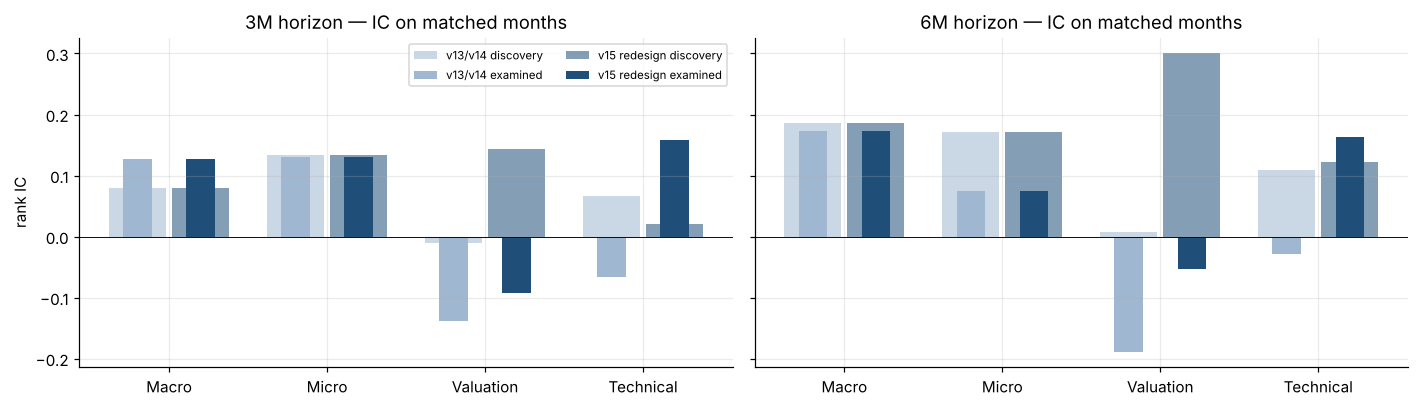

Wide bars = discovery, narrow bars = examined window.


In [22]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
pl = list(FAM); x = np.arange(4)
for ax, h in zip(axs, ('3M', '6M')):
    for i, (lab, off, col) in enumerate((('v13/v14', -0.2, '#9fb7d0'), ('v15 redesign', 0.2, '#1f4e79'))):
        d_ = [CMPV.loc[(p, h, lab), 'IC discovery'] for p in pl]; e_ = [CMPV.loc[(p, h, lab), 'IC examined'] for p in pl]
        ax.bar(x + off, d_, 0.36, color=col, alpha=.55, label=f'{lab} discovery')
        ax.bar(x + off, e_, 0.18, color=col, label=f'{lab} examined')
    ax.axhline(0, c='k', lw=.6); ax.set_xticks(x); ax.set_xticklabels(pl); ax.set_title(f'{h} horizon — IC on matched months')
axs[0].set_ylabel('rank IC'); axs[0].legend(fontsize=7.5, ncol=2)
plt.tight_layout(); plt.savefig(CH/'v13_vs_v15_ic.png', dpi=200, bbox_inches='tight'); plt.show()
print('Wide bars = discovery, narrow bars = examined window.')